# UTS 31250 Introduction to Data Analytics - Spring 2026
## Assignment 3: Flight Arrival Delay Classification & Kaggle Preiction


In [109]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.calibration import CalibratedClassifierCV

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve, precision_recall_curve,
)



### 1. Loading the Dataset

Now loading the training flight dataset to verify expected schema, and data integrity

In [110]:
train_raw = pd.read_csv("Assignment3-Flight-Dataset.csv")
sample_sub = pd.read_csv("Assignment3-Kaggle Submission-Sample.csv")
unknown_raw = pd.read_csv("Assignment3-Unknown-Dataset.csv")
print(train_raw.shape)
train_raw.head()

(42634, 16)


,O_CITY,O_STATE,D_CITY,D_STATE,DEPARTURE_TIME,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,DIVERTED,CANCELLED,DATE,AIRLINE_NAME,Arrival_Delay
0,Portland,OR,Minneapolis,MN,45,193.0,186,171,1426.0,545.0,6,0.0,0,2015-1-1,Delta Air Lines Inc.,0
1,Little Rock,AR,Dallas-Fort Worth,TX,555,80.0,75,56,304.0,703.0,7,0.0,0,2015-1-1,American Airlines Inc.,0
2,Arlington,VA,Miami,FL,605,157.0,151,130,919.0,827.0,9,0.0,0,NaN,American Airlines Inc.,0
3,Chicago,IL,Orlando,FL,603,163.0,147,127,1005.0,921.0,9,0.0,0,2015-1-1,United Air Lines Inc.,0
4,Dallas-Fort Worth,TX,Miami,FL,603,163.0,152,129,1121.0,NaN,13,0.0,0,2015-1-1,American Airlines Inc.,0


In [111]:
def missing_table(df):
    miss = df.isnull().sum()
    out = pd.DataFrame({"Missing": miss, "Percent (%)": (miss/len(df) * 100).round(2)})
    return out[out["Missing"] > 0]

train_raw.info()
print("\nMissing Values")
display(missing_table(train_raw))

<class 'pandas.DataFrame'>
RangeIndex: 42634 entries, 0 to 42633
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   O_CITY          40488 non-null  str    
 1   O_STATE         42634 non-null  str    
 2   D_CITY          42634 non-null  str    
 3   D_STATE         42634 non-null  str    
 4   DEPARTURE_TIME  42634 non-null  int64  
 5   SCHEDULED_TIME  40490 non-null  float64
 6   ELAPSED_TIME    42634 non-null  int64  
 7   AIR_TIME        42634 non-null  int64  
 8   DISTANCE        39222 non-null  float64
 9   WHEELS_ON       40198 non-null  float64
 10  TAXI_IN         42634 non-null  int64  
 11  DIVERTED        38729 non-null  float64
 12  CANCELLED       42634 non-null  int64  
 13  DATE            40429 non-null  str    
 14  AIRLINE_NAME    42634 non-null  str    
 15  Arrival_Delay   42634 non-null  int64  
dtypes: float64(4), int64(6), str(6)
memory usage: 5.2 MB

Missing Values


,Missing,Percent (%)
O_CITY,2146,5.03
SCHEDULED_TIME,2144,5.03
DISTANCE,3412,8.00
WHEELS_ON,2436,5.71
DIVERTED,3905,9.16
DATE,2205,5.17


Missing values in the training dataset includes
- O_CITY: 5.03%
- SCHEDULED_TIME: 5.03%
- DISTANCE: 8.00%
- WHEELS_ON: 5.71%
- DIVERTED: 9.16%
- DATE: 5.17%

## 2. Data Cleaning
- Zero-Variance attributes (DIVERTED, CANCELLED) hold single value, so they carry no predictive signal and are dropped
- DATE is only used to derive calendar features and is dropped afterwards
- Missing Values are imputed inside the modeling pipeline, so imputation statistics are learned from training data only.

In [112]:

for col in ["DIVERTED", "CANCELLED"]:
    tr_vals = sorted(train_raw[col].dropna().unique())
    unk_vals = sorted(unknown_raw[col].dropna().unique()) if col in unknown_raw else "n/a"
    print(f"{col}: training values {tr_vals}")

ZERO_VAR_COLS = [c for c in ["DIVERTED", "CANCELLED"] if train_raw[c].nunique(dropna=True) <= 1]
DROP_COLS = ["Arrival_Delay", "DATE"] + ZERO_VAR_COLS
print("\nZero-variance columns to drop:", ZERO_VAR_COLS)

DIVERTED: training values [np.float64(0.0)]
CANCELLED: training values [np.int64(0)]

Zero-variance columns to drop: ['DIVERTED', 'CANCELLED']


## 3. Feature Engineering
- Calendar: MONTH, DAY, DAY_OF_WEEK, IS_WEEKEND
- Departure Timing: DEP_HOUR, DEP_MIN, DEP_HOUR_SIN DEP_HOUR_COS
- Duration vs Schedule: TIME_DIFF, TIME_RATIO, - AIR_SCHED_DIFF
- Taxi/Ground time: TAXI_OUT, TOTAL_TAXI, TAXI_OUT_RATIO, TAXI_IN_RATIO, AIR_TIME_RATIO

In [113]:
def engineer_features(df):
    data = df.copy()

    # Calendar
    dates = pd.to_datetime(data["DATE"], errors="coerce")
    data["MONTH"] = dates.dt.month
    data["DAY"] = dates.dt.day
    data["DAY_OF_WEEK"] = dates.dt.dayofweek
    data["IS_WEEKEND"] = (data["DAY_OF_WEEK"] >= 5).astype(float)

    # Departure timing
    data["DEP_HOUR"] = data["DEPARTURE_TIME"] // 100
    data["DEP_MIN"] = (data["DEPARTURE_TIME"] // 100) * 60 + (data["DEPARTURE_TIME"] % 100)
    data["DEP_HOUR_SIN"] = np.sin(2 * np.pi * data["DEP_MIN"] / 1440)
    data["DEP_HOUR_COS"] = np.cos(2 * np.pi * data["DEP_MIN"] / 1440)

    # Duration vs. schedule
    data["TIME_DIFF"] = data["ELAPSED_TIME"] - data["SCHEDULED_TIME"]
    data["TIME_RATIO"] = data["ELAPSED_TIME"] / data["SCHEDULED_TIME"].replace(0, np.nan)
    data["AIR_SCHED_DIFF"] = data["AIR_TIME"] - data["SCHEDULED_TIME"]

    # Taxi / ground time
    data["TAXI_OUT"] = data["ELAPSED_TIME"] - data["AIR_TIME"] - data["TAXI_IN"]
    data["TOTAL_TAXI"] = data["TAXI_OUT"] + data["TAXI_IN"]
    data["TAXI_OUT_RATIO"] = data["TAXI_OUT"] / data["ELAPSED_TIME"].replace(0, np.nan)
    data["TAXI_IN_RATIO"] = data["TAXI_IN"] / data["ELAPSED_TIME"].replace(0, np.nan)
    data["AIR_TIME_RATIO"] = data["AIR_TIME"] / data["ELAPSED_TIME"].replace(0, np.nan)

    # Speed and arrival slippage (wrapped at midnight)
    data["SPEED"] = data["DISTANCE"] / data["AIR_TIME"].replace(0, np.nan)
    wheels_min = (data["WHEELS_ON"] // 100) * 60 + (data["WHEELS_ON"] % 100)
    sched_arr = (data["DEP_MIN"] + data["SCHEDULED_TIME"]) % 1440
    act_arr = (wheels_min + data["TAXI_IN"]) % 1440
    data["ARR_DIFF"] = ((act_arr - sched_arr + 720) % 1440) - 720

    # Routes
    data["ROUTE"] = data["O_CITY"].fillna("UNK") + "_" + data["D_CITY"].fillna("UNK")
    data["ROUTE_STATE"] = data["O_STATE"] + "_" + data["D_STATE"]
    return data

train_fe   = engineer_features(train_raw)
unknown_fe = engineer_features(unknown_raw)
print(f"Training:  {train_raw.shape[1]} -> {train_fe.shape[1]} columns")
print(f"Unknown:   {unknown_raw.shape[1]} -> {unknown_fe.shape[1]} columns")


Training:  16 -> 36 columns
Unknown:   15 -> 35 columns


## 4. Exploratory Data Analysis

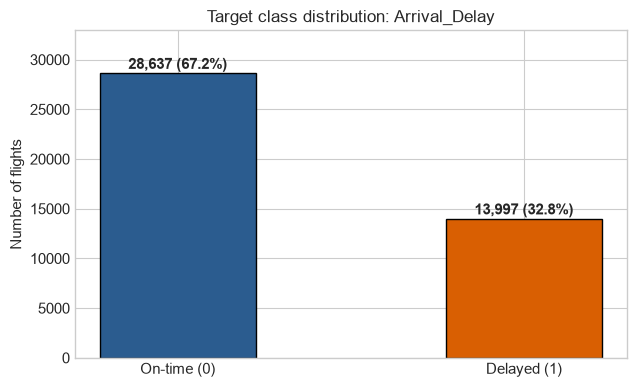

Class 0 (on time): 28,637 (67.17%)
Class 1 (delayed): 13,997 (32.83%)
Imbalance ratio:   2.05 : 1


In [114]:
counts = train_fe["Arrival_Delay"].value_counts().sort_index()
props = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(["On-time (0)", "Delayed (1)"], counts.values, color=["#2b5c8f", "#d95f02"],
              width=0.45, edgecolor="black")
for bar, pct in zip(bars, props.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.015,
            f"{int(bar.get_height()):,} ({pct:.1f}%)", ha="center", fontweight="bold")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Target class distribution: Arrival_Delay")
ax.set_ylabel("Number of flights")
plt.tight_layout(); plt.show()

print(f"Class 0 (on time): {counts[0]:,} ({props[0]:.2f}%)")
print(f"Class 1 (delayed): {counts[1]:,} ({props[1]:.2f}%)")
print(f"Imbalance ratio:   {counts[0] / counts[1]:.2f} : 1")

**Target Class Distribution Analysis:**
The target attribute `Arrival_Delay` displays moderate class imbalance: 67.17% of flights are on-time (Class 0) and 32.83% are delayed (Class 1). A naive baseline classifier that predicts only Class 0 would achieve 67.17% accuracy while failing completely on delayed flights (0% recall). Consequently, model evaluation must emphasize **ROC-AUC**, **Precision**, **Recall**, and **F1-Score** alongside overall Accuracy.


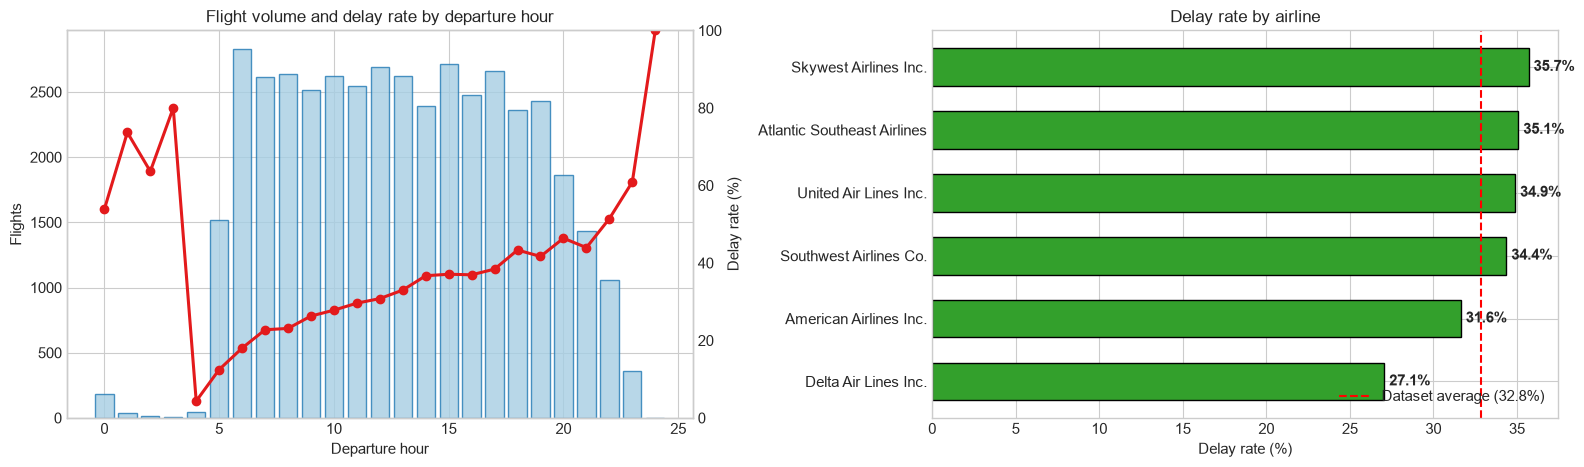

In [115]:
hourly = train_fe.groupby("DEP_HOUR")["Arrival_Delay"].agg(["count", "mean"]).reset_index()
airline = (train_fe.groupby("AIRLINE_NAME")["Arrival_Delay"].mean() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ax1 = axes[0]; ax2 = ax1.twinx()
ax1.bar(hourly["DEP_HOUR"], hourly["count"], color="#a6cee3", edgecolor="#1f78b4", alpha=0.8)
ax2.plot(hourly["DEP_HOUR"], hourly["mean"] * 100, color="#e31a1c", marker="o", linewidth=2.2)
ax1.set_xlabel("Departure hour"); ax1.set_ylabel("Flights"); ax2.set_ylabel("Delay rate (%)")
ax2.set_ylim(0, 100); ax2.grid(False)
ax1.set_title("Flight volume and delay rate by departure hour")

axes[1].barh(airline.index, airline.values, color="#33a02c", edgecolor="black", height=0.6)
axes[1].axvline(props[1], color="red", linestyle="--", label=f"Dataset average ({props[1]:.1f}%)")
for y_pos, v in enumerate(airline.values):
    axes[1].text(v + 0.3, y_pos, f"{v:.1f}%", va="center", fontweight="bold")
axes[1].set_xlabel("Delay rate (%)"); axes[1].set_title("Delay rate by airline"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Diurnal Delay Accumulation:**
The departure hour reveals a pronounced operational dynamic:
- Early morning flights (04:00 to 07:00) experience delay rates below 15-20%, because aircraft and flight crews begin the day without residual backlogs.
- As the day advances, cascading delays accumulate due to late incoming aircraft, ground turnarounds, and air traffic congestion.
- By evening (18:00 to 23:00), the delay rate exceeds 40-60%. Departure time is therefore one of the strongest predictive features.

**Airline Operational Differences:**
Delta Air Lines Inc. records the best on-time rate, with only 27.1% of its flights delayed. In contrast, regional carriers (Skywest Airlines Inc. at 35.7% and Atlantic Southeast Airlines at 35.1%) and major carriers (Southwest Airlines at 34.4% and United Air Lines at 34.9%) have higher delay rates. Airline identity provides clear discriminative information.



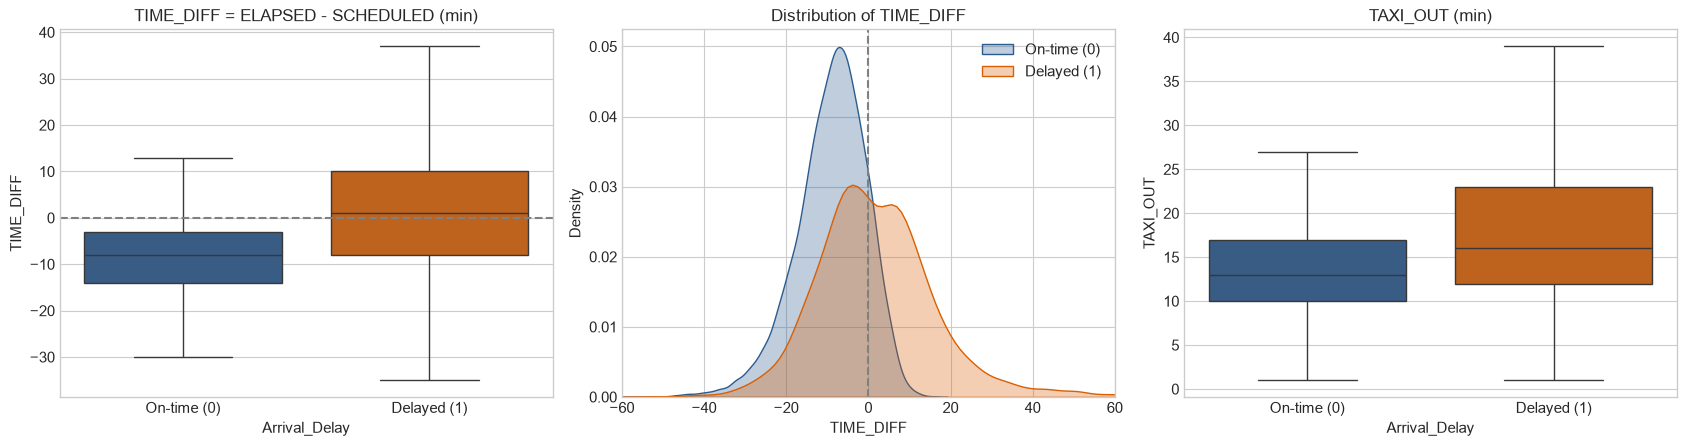

Mean TIME_DIFF by class:
Arrival_Delay
0   -9.08
1    2.13

Pearson correlation with Arrival_Delay:


,r
TIME_DIFF,0.4179
TOTAL_TAXI,0.3017
TAXI_OUT,0.2755
DEP_HOUR,0.1868
TAXI_IN,0.1317


In [116]:
# 4.3 Duration discrepancy and taxi time
pal = ["#2b5c8f", "#d95f02"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.boxplot(data=train_fe, x="Arrival_Delay", y="TIME_DIFF", hue="Arrival_Delay", palette=pal,
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_xticklabels(["On-time (0)", "Delayed (1)"]); axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("TIME_DIFF = ELAPSED - SCHEDULED (min)")

for cls, label, color in [(0, "On-time (0)", pal[0]), (1, "Delayed (1)", pal[1])]:
    sns.kdeplot(train_fe.loc[train_fe["Arrival_Delay"] == cls, "TIME_DIFF"].dropna(), ax=axes[1],
                label=label, color=color, fill=True, alpha=0.3)
axes[1].set_xlim(-60, 60); axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set_title("Distribution of TIME_DIFF"); axes[1].legend()

sns.boxplot(data=train_fe, x="Arrival_Delay", y="TAXI_OUT", hue="Arrival_Delay", palette=pal,
            legend=False, showfliers=False, ax=axes[2])
axes[2].set_xticklabels(["On-time (0)", "Delayed (1)"]); axes[2].set_title("TAXI_OUT (min)")
plt.tight_layout(); plt.show()

print("Mean TIME_DIFF by class:")
print(train_fe.groupby("Arrival_Delay")["TIME_DIFF"].mean().round(2).to_string())

corr_feats = ["TIME_DIFF", "TOTAL_TAXI", "TAXI_OUT", "DEP_HOUR", "TAXI_IN"]
corr_target = train_fe[corr_feats + ["Arrival_Delay"]].corr()["Arrival_Delay"].drop("Arrival_Delay")
print("\nPearson correlation with Arrival_Delay:")
display(corr_target.sort_values(ascending=False).round(4).to_frame("r"))

**Flight Duration Discrepancy:**
The difference between actual flight duration and scheduled flight duration (`TIME_DIFF = ELAPSED_TIME - SCHEDULED_TIME`) is highly informative:
- Flights that arrive on time take an average of **9.08 minutes less** than scheduled.
- Flights that are delayed take an average of **2.13 minutes longer** than scheduled.
This feature directly reflects en-route holding patterns, air vectoring, and airport congestion.


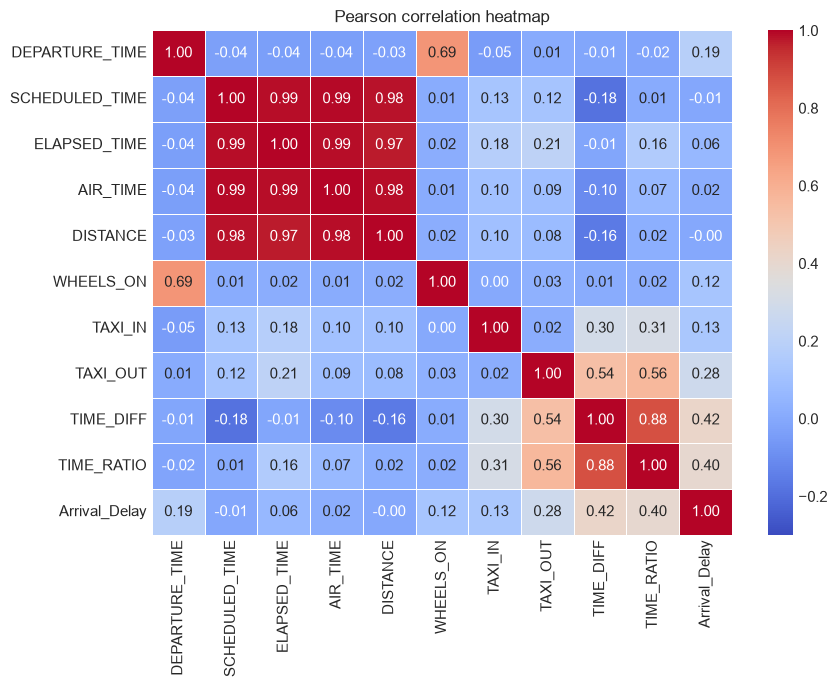

In [117]:
# 4.4 Correlation heatmap of the numeric attributes
heat_cols = ["DEPARTURE_TIME", "SCHEDULED_TIME", "ELAPSED_TIME", "AIR_TIME", "DISTANCE", "WHEELS_ON",
             "TAXI_IN", "TAXI_OUT", "TIME_DIFF", "TIME_RATIO", "Arrival_Delay"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_fe[heat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.3, vmax=1.0,
            linewidths=0.5, ax=ax)
ax.set_title("Pearson correlation heatmap")
plt.tight_layout(); plt.show()

## 5. Training split and Pre-Processing


In [118]:
X = train_fe.drop(columns=DROP_COLS)
y = train_fe["Arrival_Delay"]

missing_cols = [c for c in X.columns if c not in train_fe.columns]
assert not missing_cols, f"Unknown set lacks columns present in training: {missing_cols}"
X_unk = unknown_fe[X.columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

TARGET_ENC_COLS = ["O_CITY", "D_CITY", "ROUTE"]
ONE_HOT_COLS    = ["O_STATE", "D_STATE", "AIRLINE_NAME", "ROUTE_STATE"]
NUM_COLS        = [c for c in X.columns if c not in TARGET_ENC_COLS + ONE_HOT_COLS]

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median", add_indicator=True)),
            ("sc", StandardScaler()),
        ]), NUM_COLS),
        ("te", Pipeline([
            ("imp", SimpleImputer(strategy="constant", fill_value="UNK")),
            ("target_enc", TargetEncoder(smooth="auto", cv=5, shuffle=True, random_state=42)),
        ]), TARGET_ENC_COLS),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
        ]), ONE_HOT_COLS),
    ])

def make_pipeline(clf):
    return Pipeline([("prep", make_preprocessor()), ("clf", clf)])

print(f"Training rows: {len(X_train):,}   Test rows: {len(X_test):,}   Unknown rows: {len(X_unk):,}")
print(f"Numeric: {len(NUM_COLS)}   Target-encoded: {len(TARGET_ENC_COLS)}   One-hot: {len(ONE_HOT_COLS)}")
print(f"Delay rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

Training rows: 34,107   Test rows: 8,527   Unknown rows: 21,318
Numeric: 25   Target-encoded: 3   One-hot: 4
Delay rate  train: 0.3283   test: 0.3283


## Baseline Training
Using five classifier with no class weights and evaluated at the default 0.50 probability threshold

In [119]:
def make_classifiers(weighted):
    cw, rf_cw = ("balanced", "balanced_subsample") if weighted else (None, None)
    return {
        "Decision Tree": DecisionTreeClassifier(
            criterion="gini", max_depth=8, min_samples_leaf=25, class_weight=cw, random_state=42),
        "K-Nearest Neighbour": KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1),
        "Random Forest": RandomForestClassifier(
            n_estimators=250, max_depth=16, min_samples_leaf=10, class_weight=rf_cw,
            random_state=42, n_jobs=-1),
        "Support Vector Machine": CalibratedClassifierCV(
            LinearSVC(dual=False, C=0.5, class_weight=cw, random_state=42, max_iter=2000), cv=3),
        "Neural Network": MLPClassifier(
            hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=0.01,
            learning_rate_init=0.001, max_iter=150, early_stopping=True, validation_fraction=0.1,
            n_iter_no_change=10, random_state=42),
    }

def predict_at(proba, tau=0.5):
    return (np.asarray(proba) >= tau).astype(int)

def score_at(y_true, proba, tau=0.5):
    pred = predict_at(proba, tau)
    return {
        "Accuracy":  accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall":    recall_score(y_true, pred, zero_division=0),
        "F1":        f1_score(y_true, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, proba),
    }

def fit_and_score(name, clf, tau=0.5):
    pipe = make_pipeline(clf)
    t0 = time.time()
    pipe.fit(X_train, y_train)
    fit_time = time.time() - t0
    proba = pipe.predict_proba(X_test)[:, 1]
    res = {"pipe": pipe, "proba": proba, "fit_time": fit_time, **score_at(y_test, proba, tau)}
    print(f"{name:<24} F1={res['F1']:.4f}  Prec={res['Precision']:.4f}  Rec={res['Recall']:.4f}  "
          f"Acc={res['Accuracy']:.4f}  AUC={res['ROC-AUC']:.4f}  ({fit_time:.1f}s)")
    return res

In [120]:
baseline = {}
for name, clf in make_classifiers(weighted=False).items():
    baseline[name] = fit_and_score(name, clf, tau=0.5)

Decision Tree            F1=0.5905  Prec=0.7640  Rec=0.4812  Acc=0.7809  AUC=0.7981  (1.0s)
K-Nearest Neighbour      F1=0.5084  Prec=0.7932  Rec=0.3741  Acc=0.7625  AUC=0.7808  (0.3s)
Random Forest            F1=0.5790  Prec=0.8356  Rec=0.4430  Acc=0.7886  AUC=0.8186  (4.3s)
Support Vector Machine   F1=0.5759  Prec=0.7325  Rec=0.4745  Acc=0.7706  AUC=0.7794  (1.9s)
Neural Network           F1=0.5864  Prec=0.7943  Rec=0.4648  Acc=0.7848  AUC=0.8039  (3.5s)


,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (s)
Decision Tree,0.7809,0.7640,0.4812,0.5905,0.7981,1.0168
Neural Network,0.7848,0.7943,0.4648,0.5864,0.8039,3.4921
Random Forest,0.7886,0.8356,0.4430,0.5790,0.8186,4.2548
Support Vector Machine,0.7706,0.7325,0.4745,0.5759,0.7794,1.8816
K-Nearest Neighbour,0.7625,0.7932,0.3741,0.5084,0.7808,0.3092


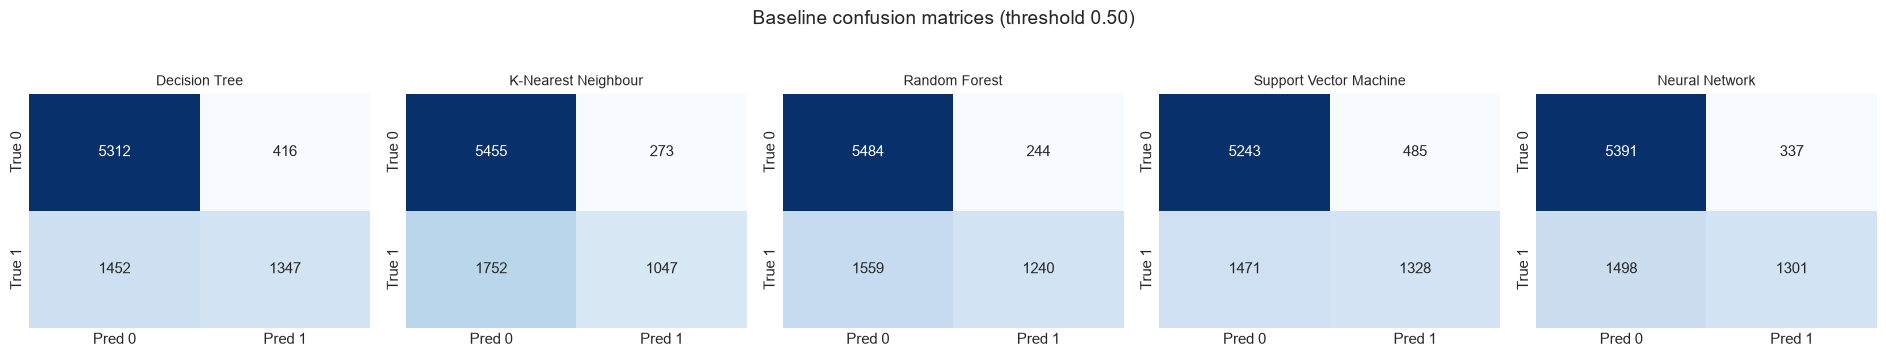

In [121]:
baseline_df = pd.DataFrame({
    n: {k: r[k] for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "fit_time"]}
    for n, r in baseline.items()
}).T.rename(columns={"fit_time": "Fit time (s)"}).sort_values("F1", ascending=False)
display(baseline_df.round(4))

fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, (name, res) in zip(axes, baseline.items()):
    sns.heatmap(confusion_matrix(y_test, predict_at(res["proba"], 0.5)), annot=True, fmt="d", cmap="Blues",
                cbar=False, xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], ax=ax)
    ax.set_title(name, fontsize=10)
plt.suptitle("Baseline confusion matrices (threshold 0.50)", y=1.04)
plt.tight_layout(); plt.show()

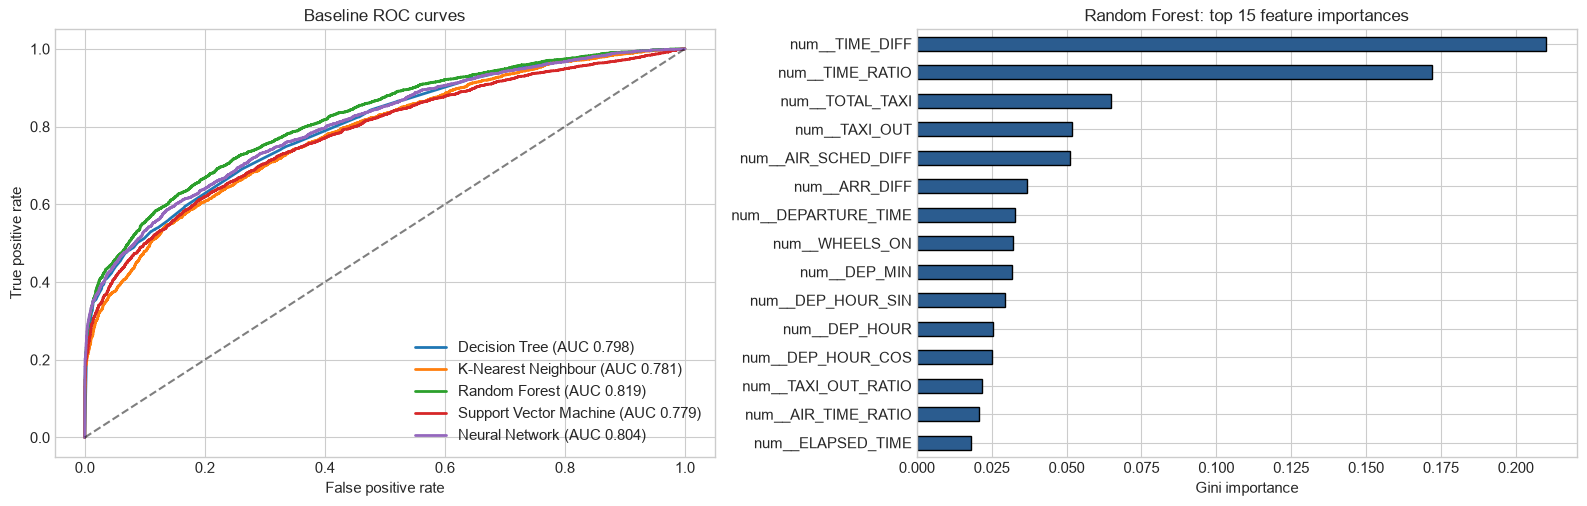

,importance
num__TIME_DIFF,0.2099
num__TIME_RATIO,0.1721
num__TOTAL_TAXI,0.0650
num__TAXI_OUT,0.0518
num__AIR_SCHED_DIFF,0.0513
num__ARR_DIFF,0.0367
num__DEPARTURE_TIME,0.0326
num__WHEELS_ON,0.0321
num__DEP_MIN,0.0317
num__DEP_HOUR_SIN,0.0296


In [122]:
# Baseline ROC curves and Random Forest feature importance
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for name, res in baseline.items():
    fpr, tpr, _ = roc_curve(y_test, res["proba"])
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC {res['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("Baseline ROC curves"); axes[0].legend(loc="lower right")

rf_pipe = baseline["Random Forest"]["pipe"]
importances = pd.Series(
    rf_pipe.named_steps["clf"].feature_importances_,
    index=rf_pipe.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False)
importances.head(15).sort_values().plot(kind="barh", color="#2b5c8f", edgecolor="black", ax=axes[1])
axes[1].set_title("Random Forest: top 15 feature importances"); axes[1].set_xlabel("Gini importance")
plt.tight_layout(); plt.show()
display(importances.head(10).round(4).to_frame("importance"))

# F1. Optimization
Since the kaggle competition use F-Score, the models will be tuned on the delayed class in two steps:
1. Cost-Sensitive Learning. class_weight="balanced" on Decision Tree, Random Forest and SVM. KNN and neural network have no class-weight option so they are unchanged for this step.
2. Threshold tuning. The decision threshold is moved from 0.50 to the value that maximises F1 over a grid of 0.15 to 0.70. THRESHOLD_SOURCE in the configuration cell controls whether that value is chosen out-of-fold training predictions ("oof", default) or from the test split

### 7.1 Class weighting

In [123]:
THRESHOLD_SOURCE = "oof"
THRESHOLD_GRID   = np.round(np.arange(0.15, 0.7001, 0.01), 2)

In [124]:
weighted = {}
for name, clf in make_classifiers(weighted=True).items():
    weighted[name] = fit_and_score(name, clf, tau=0.5)

Decision Tree            F1=0.6249  Prec=0.6644  Rec=0.5899  Acc=0.7676  AUC=0.7991  (1.1s)
K-Nearest Neighbour      F1=0.5084  Prec=0.7932  Rec=0.3741  Acc=0.7625  AUC=0.7808  (0.3s)
Random Forest            F1=0.6394  Prec=0.6574  Rec=0.6224  Acc=0.7696  AUC=0.8188  (4.4s)
Support Vector Machine   F1=0.5706  Prec=0.7215  Rec=0.4720  Acc=0.7669  AUC=0.7807  (1.5s)
Neural Network           F1=0.5864  Prec=0.7943  Rec=0.4648  Acc=0.7848  AUC=0.8039  (3.6s)


7.2 Step 2: threshold tuning

In [125]:
def f1_curve(y_true, proba, grid=THRESHOLD_GRID):
    return np.array([f1_score(y_true, predict_at(proba, t), zero_division=0) for t in grid])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned = {}

for name, clf in make_classifiers(weighted=True).items():
    if THRESHOLD_SOURCE == "oof":
        tune_proba = cross_val_predict(make_pipeline(clf), X_train, y_train, cv=cv,
                                       method="predict_proba")[:, 1]
        tune_y = y_train.to_numpy()
    elif THRESHOLD_SOURCE == "test":
        tune_proba, tune_y = weighted[name]["proba"], y_test.to_numpy()
    else:
        raise ValueError("THRESHOLD_SOURCE must be 'oof' or 'test'")

    tune_curve = f1_curve(tune_y, tune_proba)
    tau = float(THRESHOLD_GRID[int(np.argmax(tune_curve))])

    test_proba = weighted[name]["proba"]
    test_curve = f1_curve(y_test, test_proba)           # for reference / plotting only
    tuned[name] = {
        "tau": tau,
        "tune_curve": tune_curve,
        "test_curve": test_curve,
        "oracle_f1": float(test_curve.max()),           # best F1 achievable on test (optimistic)
        **score_at(y_test, test_proba, tau),
    }
    print(f"{name:<24} tau*={tau:.2f}  test F1={tuned[name]['F1']:.4f}  "
          f"(Prec={tuned[name]['Precision']:.4f}, Rec={tuned[name]['Recall']:.4f})")

Decision Tree            tau*=0.52  test F1=0.6263  (Prec=0.6680, Rec=0.5895)
K-Nearest Neighbour      tau*=0.28  test F1=0.6041  (Prec=0.5261, Rec=0.7092)
Random Forest            tau*=0.47  test F1=0.6450  (Prec=0.6156, Rec=0.6774)
Support Vector Machine   tau*=0.38  test F1=0.6066  (Prec=0.5953, Rec=0.6184)
Neural Network           tau*=0.32  test F1=0.6248  (Prec=0.6051, Rec=0.6459)


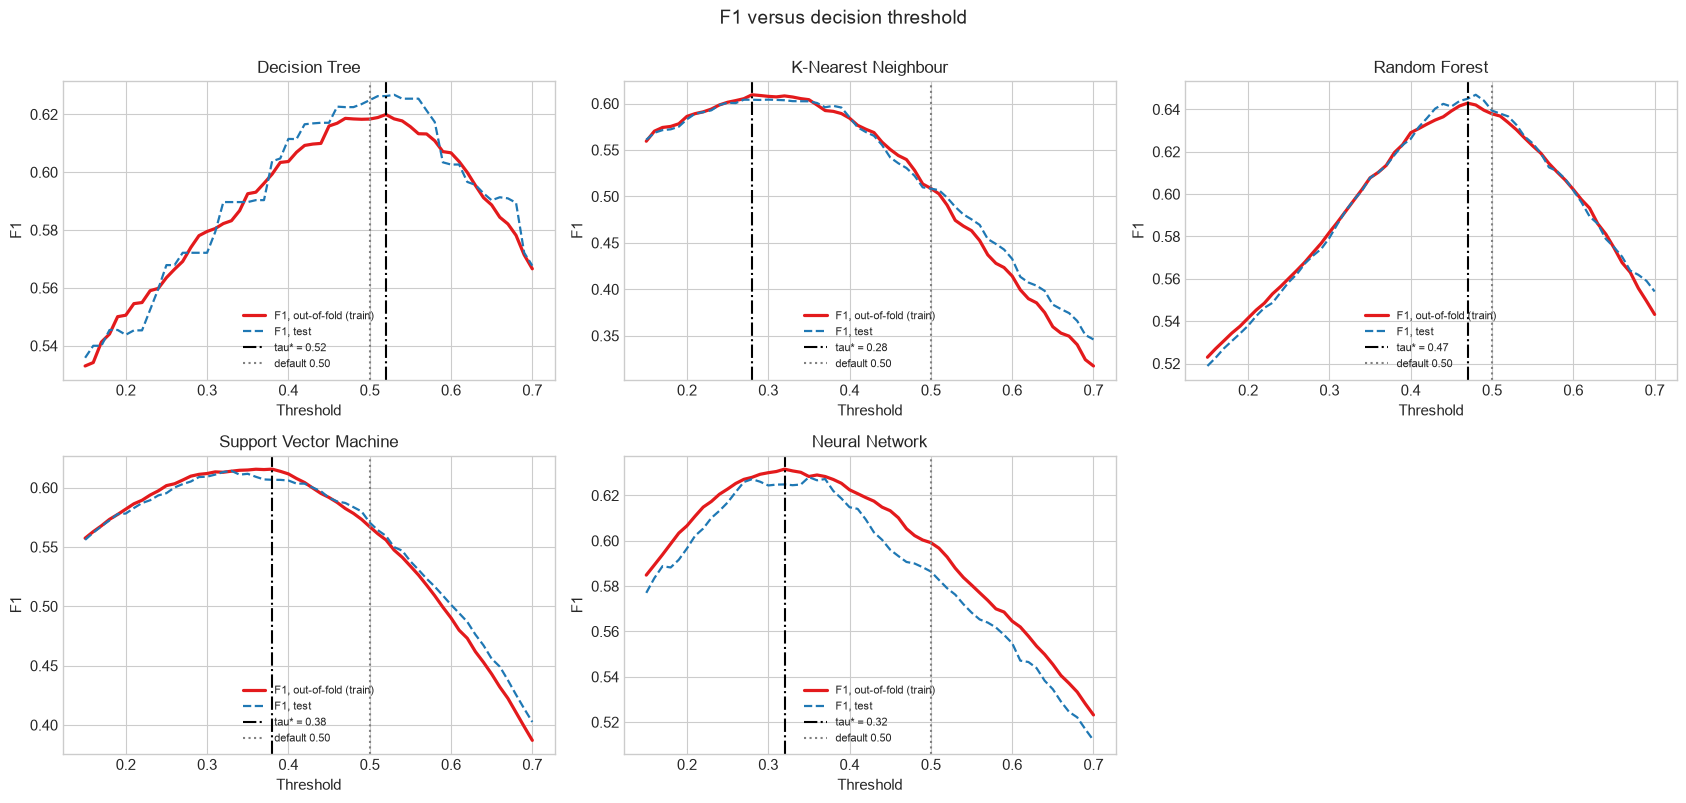

In [126]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (name, res) in zip(axes.ravel(), tuned.items()):
    src = "out-of-fold (train)" if THRESHOLD_SOURCE == "oof" else "test"
    ax.plot(THRESHOLD_GRID, res["tune_curve"], color="#e31a1c", linewidth=2.3, label=f"F1, {src}")
    ax.plot(THRESHOLD_GRID, res["test_curve"], color="#1f78b4", linewidth=1.6, linestyle="--", label="F1, test")
    ax.axvline(res["tau"], color="black", linestyle="-.", label=f"tau* = {res['tau']:.2f}")
    ax.axvline(0.5, color="gray", linestyle=":", label="default 0.50")
    ax.set_title(name); ax.set_xlabel("Threshold"); ax.set_ylabel("F1"); ax.legend(fontsize=8, loc="lower center")
axes.ravel()[-1].axis("off")
plt.suptitle("F1 versus decision threshold", y=1.0)
plt.tight_layout(); plt.show()

In [127]:
rows = []
for name in baseline:
    b, w, t = baseline[name], weighted[name], tuned[name]
    rows.append({
        "Classifier": name,
        "Baseline F1 (0.50)": b["F1"],
        "Weighted F1 (0.50)": w["F1"],
        "Optimal tau": t["tau"],
        "Optimized F1": t["F1"],
        "Precision": t["Precision"],
        "Recall": t["Recall"],
        "Accuracy": t["Accuracy"],
        "ROC-AUC": w["ROC-AUC"],
        "F1 gain vs baseline (%)": (t["F1"] - b["F1"]) / b["F1"] * 100,
        "Test-tuned F1 (optimistic)": t["oracle_f1"],
    })
comparison = pd.DataFrame(rows).set_index("Classifier").sort_values("Optimized F1", ascending=False)
display(comparison.round(4))
champion = comparison.index[0]
print(f"Champion by optimized F1: {champion}")

,Baseline F1 (0.50),Weighted F1 (0.50),Optimal tau,Optimized F1,Precision,Recall,Accuracy,ROC-AUC,F1 gain vs baseline (%),Test-tuned F1 (optimistic)
Classifier,,,,,,,,,,
Random Forest,0.5790,0.6394,0.47,0.6450,0.6156,0.6774,0.7552,0.8188,11.3939,0.6469
Decision Tree,0.5905,0.6249,0.52,0.6263,0.6680,0.5895,0.7691,0.7991,6.0580,0.6268
Neural Network,0.5864,0.5864,0.32,0.6248,0.6051,0.6459,0.7454,0.8039,6.5509,0.6281
Support Vector Machine,0.5759,0.5706,0.38,0.6066,0.5953,0.6184,0.7367,0.7807,5.3369,0.6141
K-Nearest Neighbour,0.5084,0.5084,0.28,0.6041,0.5261,0.7092,0.6949,0.7808,18.8251,0.6042


Champion by optimized F1: Random Forest


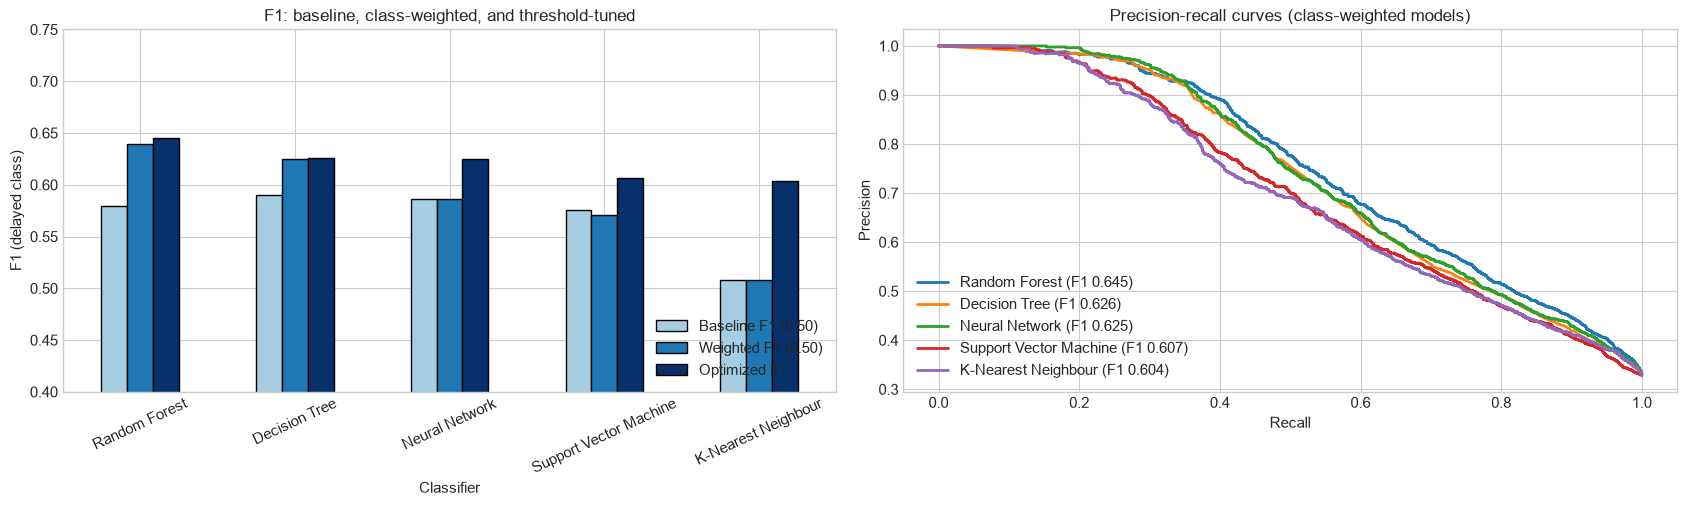

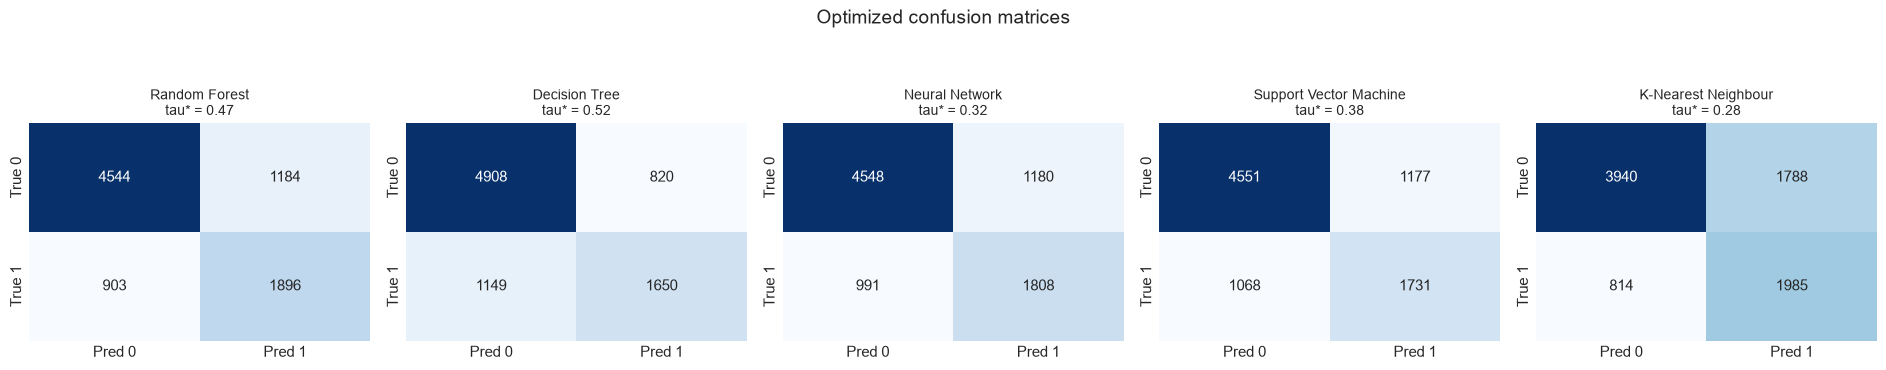

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))

plot_df = comparison[["Baseline F1 (0.50)", "Weighted F1 (0.50)", "Optimized F1"]]
plot_df.plot(kind="bar", ax=axes[0], color=["#a6cee3", "#1f78b4", "#08306b"], edgecolor="black")
axes[0].set_ylabel("F1 (delayed class)"); axes[0].set_title("F1: baseline, class-weighted, and threshold-tuned")
axes[0].tick_params(axis="x", rotation=25); axes[0].set_ylim(0.4, max(0.75, plot_df.values.max() + 0.05))
axes[0].legend(loc="lower right")

for name in comparison.index:
    p, r, _ = precision_recall_curve(y_test, weighted[name]["proba"])
    axes[1].plot(r, p, linewidth=2, label=f"{name} (F1 {tuned[name]['F1']:.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (class-weighted models)"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, name in zip(axes, comparison.index):
    cm = confusion_matrix(y_test, predict_at(weighted[name]["proba"], tuned[name]["tau"]))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], ax=ax)
    ax.set_title(f"{name}\ntau* = {tuned[name]['tau']:.2f}", fontsize=10)
plt.suptitle("Optimized confusion matrices", y=1.08)
plt.tight_layout(); plt.show()

# Kaggle Prediction files


In [130]:
FILE_KEYS = {
    "Decision Tree": "decision_tree",
    "K-Nearest Neighbour": "knn",
    "Random Forest": "random_forest",
    "Support Vector Machine": "svm",
    "Neural Network": "neural_network",
}

id_col, pred_col = sample_sub.columns[0], sample_sub.columns[1]
row_ids = sample_sub[id_col].to_numpy()
assert len(row_ids) == len(X_unk), "Sample submission and unknown dataset have different lengths"

summary, submissions = [], {}
for name, clf in make_classifiers(weighted=True).items():
    t0 = time.time()
    pipe = make_pipeline(clf).fit(X, y)
    proba_unk = pipe.predict_proba(X_unk)[:, 1]
    preds = predict_at(proba_unk, tuned[name]["tau"])

    sub = pd.DataFrame({id_col: row_ids, pred_col: preds})
    filename = f"ida_a3_26460220_{FILE_KEYS[name]}.csv"
    sub.to_csv(filename, index=False)
    submissions[name] = sub

    valid = (sub.shape == sample_sub.shape) and set(sub[pred_col].unique()) <= {0, 1}
    summary.append({
        "Model": name, "File": filename, "tau*": tuned[name]["tau"],
        "Predicted delayed": f"{int(preds.sum()):,} ({preds.mean() * 100:.1f}%)",
        "Predicted on time": f"{int((preds == 0).sum()):,} ({(1 - preds.mean()) * 100:.1f}%)",
        "Format check": "Pass" if valid else "FAIL",
        "Time (s)": round(time.time() - t0, 1),
    })

display(pd.DataFrame(summary))

champion_file = f"ida_a3_26460220.csv"
submissions[champion].to_csv(champion_file, index=False)
print(f"Primary submission ({champion}) saved as {champion_file}")

,Model,File,tau*,Predicted delayed,Predicted on time,Format check,Time (s)
0,Decision Tree,ida_a3_26460220_decision_tree.csv,0.52,"5,438 (25.5%)","15,880 (74.5%)",Pass,1.4
1,K-Nearest Neighbour,ida_a3_26460220_knn.csv,0.28,"9,212 (43.2%)","12,106 (56.8%)",Pass,24.9
2,Random Forest,ida_a3_26460220_random_forest.csv,0.47,"7,757 (36.4%)","13,561 (63.6%)",Pass,6.2
3,Support Vector Machine,ida_a3_26460220_svm.csv,0.38,"6,925 (32.5%)","14,393 (67.5%)",Pass,3.2
4,Neural Network,ida_a3_26460220_neural_network.csv,0.32,"7,061 (33.1%)","14,257 (66.9%)",Pass,12.4


Primary submission (Random Forest) saved as ida_a3_26460220.csv
